# Рекуррентный график цены биткоина

Два рисунка одной и той же ячейки из старого ноутбука, заголовок **Recurrence Graph of Bitcoin Price Patterns**.

Ряд — дневной Bitstamp BTC/USD, как в `pd.read_csv("../data/BTC_1d.csv")`: 4622 строки с `2012-01-01`, первая свеча `4.39 / 4.58 / 4.39 / 4.58`. Подпись даты на сутки впереди открытия свечи, так она совпадает с той распечаткой. `Volume` там был в долларах, здесь объём Bitstamp в BTC. График читает только `Close`.

Параметры ячейки: `log(Close)`, `RecurrencePlot(threshold="point", percentage=3, dimension=1)`, белая цена с `alpha=0.2`, халвинги `2012-11-28`, `2016-07-09`, `2020-05-11`, `2024-04-20`, палитра `viridis`. `interpolation_stage="data"` оставляет бирюзу диагонали: matplotlib 3.11 иначе смешивает уже покрашенные пиксели.

Сначала окно поста, `2012-01-01` — `2024-08-26`. Затем тот же график на всём файле, до последней свечи.


## Данные


In [1]:
from datetime import datetime
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpec
from pyts.image import RecurrencePlot

root = Path.cwd()
if not (root / "data" / "BTC_1d.csv").exists():
    root = root.parent

btc_df = pd.read_csv(root / "data" / "BTC_1d.csv", parse_dates=["Date"], index_col="Date")
btc_df.index.name = "Date"
btc_data = btc_df.copy()

print(
    f"{btc_data.index.min().date()} — {btc_data.index.max().date()}, "
    f"строк: {len(btc_data)}, close: {btc_data['Close'].iloc[-1]:.2f}"
)
btc_data.head()


2012-01-01 — 2026-10-22, строк: 5409, close: 84547.48


,Open,High,Low,Close,Volume
Date,,,,,
2012-01-01,4.39,4.58,4.39,4.58,95.317878
2012-01-02,4.58,5.00,4.58,5.00,21.602000
2012-01-03,5.00,5.00,5.00,5.00,19.048000
2012-01-04,5.32,5.32,5.14,5.29,88.037281
2012-01-05,4.93,5.57,4.93,5.57,107.233260


## График


2012-01-01 — 2024-08-26, строк: 4622 -> /workspace/output/bitcoin_recurrence_price_plot.png


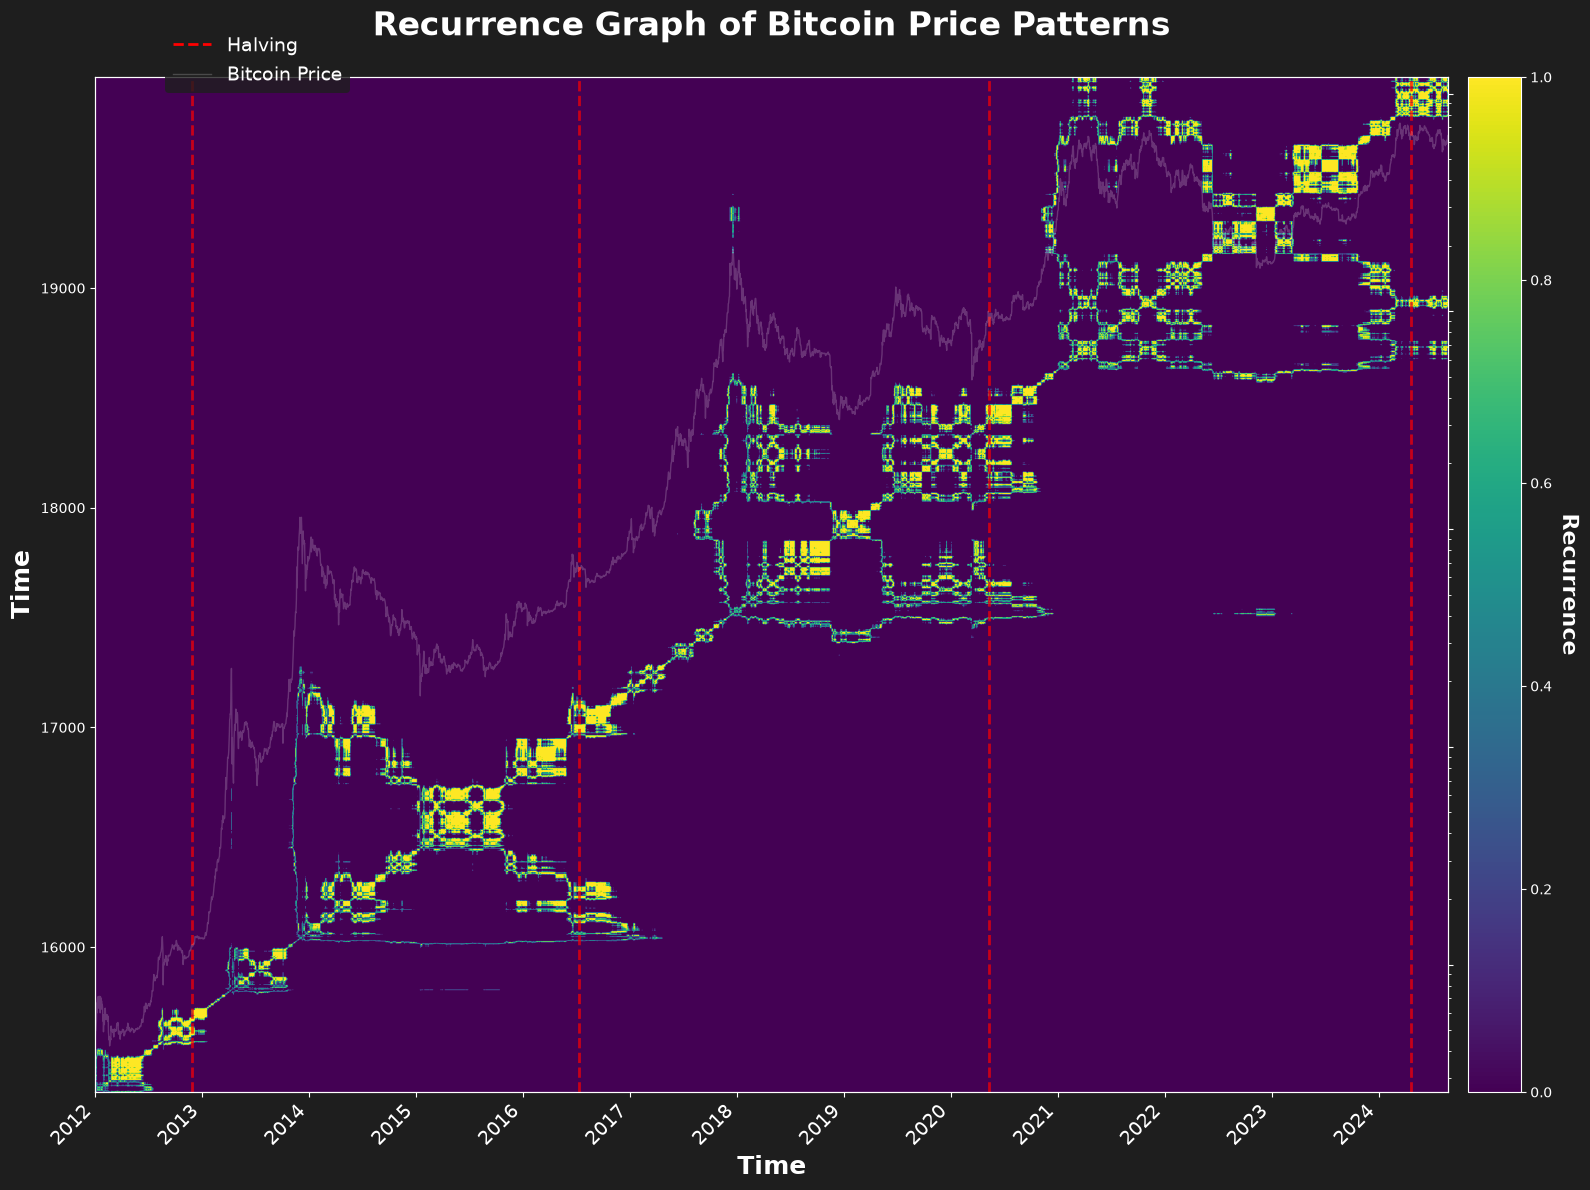

In [2]:
HALVING_DATES = [
    datetime(2012, 11, 28),
    datetime(2016, 7, 9),
    datetime(2020, 5, 11),
    datetime(2024, 4, 20),
]
ORIGINAL_START = "2012-01-01"
ORIGINAL_END = "2024-08-26"


def recurrence_graph(frame, out_path):
    # .copy(): numpy 2 отдаёт массив только для чтения, numba внутри pyts его не принимает.
    close = np.ascontiguousarray(np.log(frame["Close"].to_numpy(dtype=float)))
    rp = RecurrencePlot(threshold="point", percentage=3, dimension=1)
    matrix = rp.fit_transform(close.reshape(1, -1).copy())[0]

    plt.style.use("dark_background")
    fig = plt.figure(figsize=(16, 12))
    gs = GridSpec(1, 20, figure=fig)
    ax1 = fig.add_subplot(gs[0, :19])
    cax = fig.add_subplot(gs[0, 19])
    ax2 = ax1.twinx()

    im = ax1.imshow(
        matrix,
        cmap="viridis",
        aspect="auto",
        interpolation_stage="data",
        extent=[
            mdates.date2num(frame.index[0]),
            mdates.date2num(frame.index[-1]),
            mdates.date2num(frame.index[0]),
            mdates.date2num(frame.index[-1]),
        ],
        origin="lower",
    )
    ax1.set_title(
        "Recurrence Graph of Bitcoin Price Patterns",
        fontsize=24,
        fontweight="bold",
        pad=30,
    )
    ax1.set_xlabel("Time", fontsize=18, fontweight="bold")
    ax1.set_ylabel("Time", fontsize=18, fontweight="bold")

    ax2.plot(frame.index, frame["Close"], color="white", alpha=0.2, linewidth=1)
    ax2.tick_params(axis="y", labelcolor="white", labelsize=14)
    ax2.set_yscale("log")
    ax2.set_yticklabels([])

    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax1.xaxis.set_major_locator(mdates.YearLocator())
    plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha="right", fontsize=14)

    for date in HALVING_DATES:
        if frame.index[0] <= date <= frame.index[-1]:
            ax1.axvline(x=mdates.date2num(date), color="red", linestyle="--", alpha=0.7, linewidth=2)

    ax1.plot([], [], color="red", linestyle="--", label="Halving", linewidth=2)
    ax2.plot([], [], color="white", label="Bitcoin Price", linewidth=1, alpha=0.2)
    fig.legend(
        loc="upper left",
        bbox_to_anchor=(0.1, 0.98),
        fontsize=14,
        facecolor="#1E1E1E",
        edgecolor="none",
    )
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label("Recurrence", rotation=270, labelpad=20, fontsize=16, fontweight="bold")
    fig.patch.set_facecolor("#1E1E1E")
    plt.tight_layout()

    out_path.parent.mkdir(exist_ok=True)
    fig.savefig(out_path, dpi=100, bbox_inches="tight")
    print(f"{frame.index.min().date()} — {frame.index.max().date()}, строк: {len(frame)} -> {out_path}")
    plt.show()


original = btc_data.loc[ORIGINAL_START:ORIGINAL_END]
recurrence_graph(original, root / "output" / "bitcoin_recurrence_price_plot.png")


## Продлённый период

Тот же график на всём `data/BTC_1d.csv`. Файл докачан дневками Bitstamp после `2024-08-26` до последней доступной свечи.


2012-01-01 — 2026-10-22, строк: 5409 -> /workspace/output/bitcoin_recurrence_price_plot_extended.png


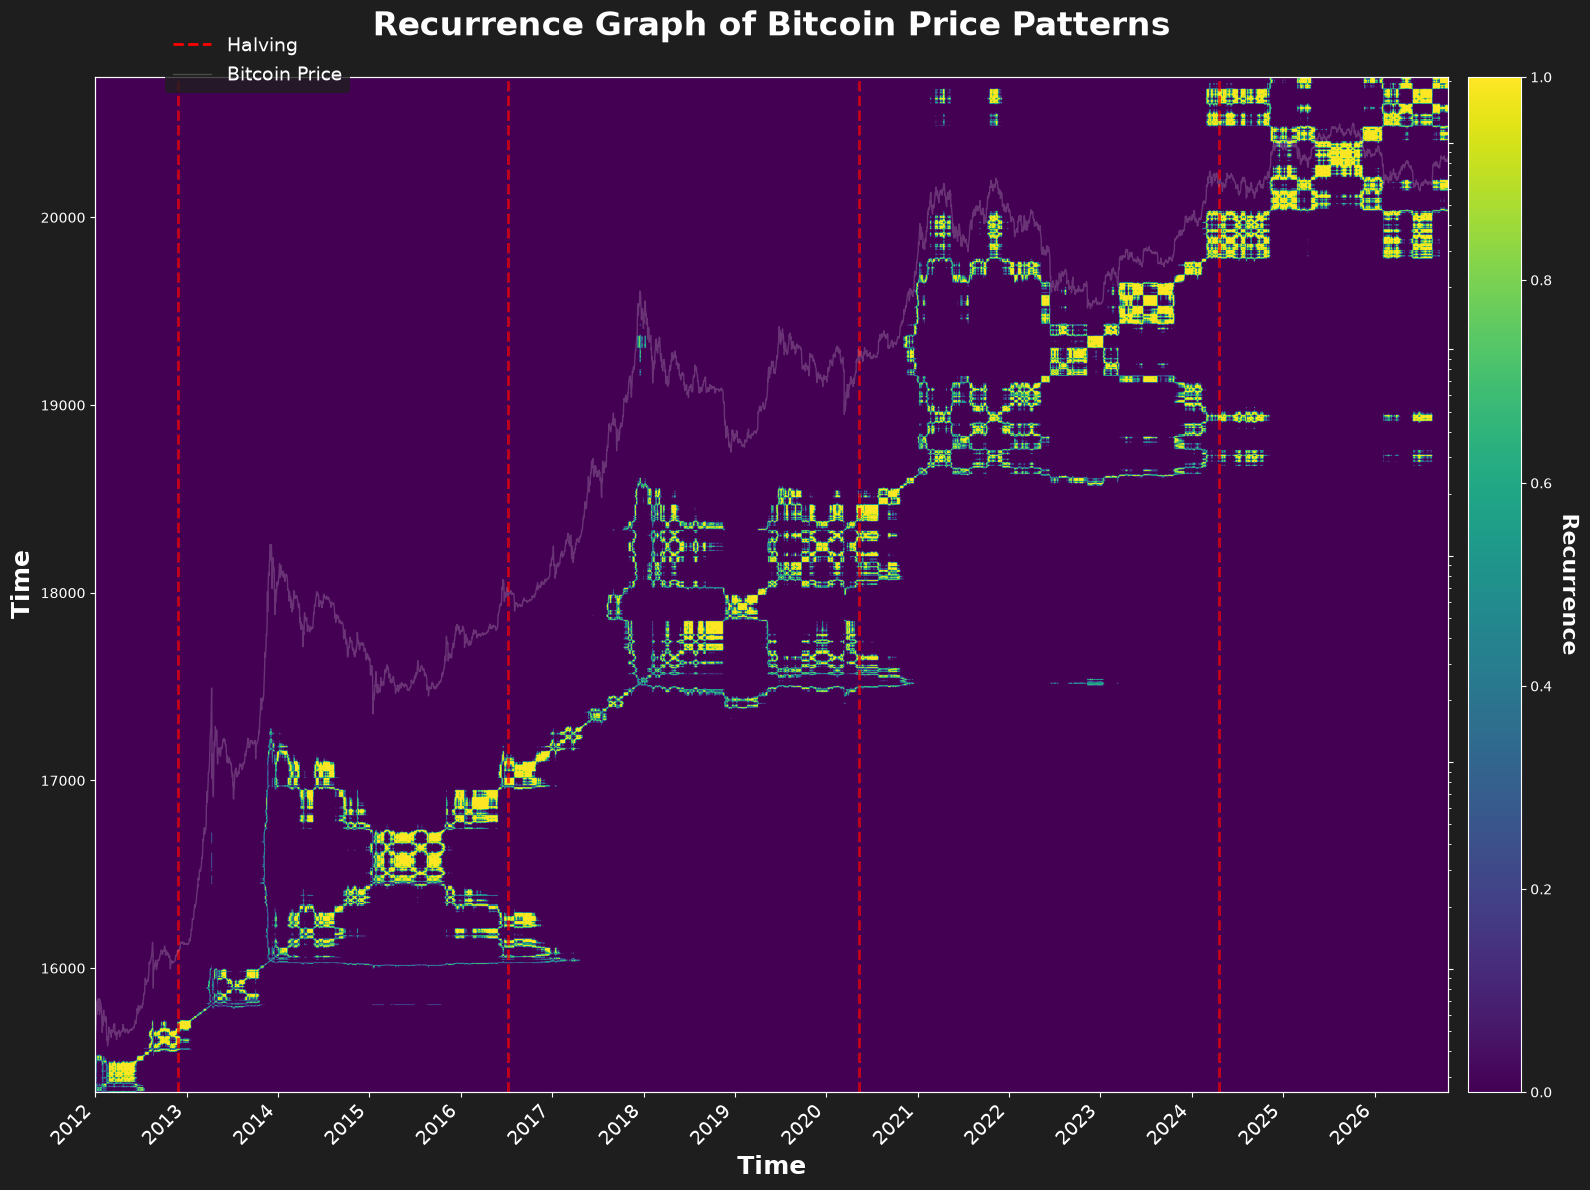

In [3]:
recurrence_graph(btc_data, root / "output" / "bitcoin_recurrence_price_plot_extended.png")
